# TP Pandas de Eleve 1 et Eleve 2

Vous pouvez faire des cellules de type Markdown pour écrire du texte.
En mettant des # vous pouvez créer des titres et sous titre

## Todo:
* Télécharger un dataset sur data.gouv.fr
* Le référencer via son lien
* Etudier ce dataset sur pandas
* Garder les output des cellules
* Vérifier que toutes les cellules marchent
* Avant de rendre, faire Kernel -> Restart Kernel and run all cells
* Faire l'évaluation du cours

In [1]:
import pandas as pd

In [ ]:
df = pd.read_csv('C:/Users/Math/cours-info/prix-controle-technique.csv', sep=";", index_col='﻿cct_siret') 
# Lien: https://www.data.gouv.fr/datasets/prix-des-controles-techniques?resource_id=63b62549-6c19-465f-a97c-2c65e9550d8a
#Attention, il y aun caractère invisible devant 'cct_siret'
df=df[['code_departement', 'cat_vehicule_id', 'cat_energie_id', 'prix_visite', 'date_application_visite']]
df


C:\Users\Math\AppData\Local\Temp\ipykernel_3524\3079504672.py:1: DtypeWarning: Columns (0: nom_departement) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('C:/Users/Math/cours-info/prix-controle-technique.csv', sep=";", index_col='﻿cct_siret')


,code_departement,cat_vehicule_id,cat_energie_id,prix_visite,date_application_visite
﻿cct_siret,,,,,
98525263400011,1,6,6,72.0,2026-04-22
51868567200033,22,6,6,55.0,2026-03-12
98533764100015,21,6,6,45.0,2026-08-17
98525263400011,1,7,6,72.0,2026-04-22
51868567200033,22,7,6,55.0,2026-03-12
...,...,...,...,...,...
87770014600013,38,5,1,80.0,2020-09-08
87770014600013,38,5,2,80.0,2020-09-08
87770014600013,38,5,3,100.0,2020-09-08


In [ ]:
#Pour chaque départment, la moyenne des prix de consulation en fonction du type de véhicule 
df.groupby(['code_departement', 'cat_vehicule_id']).prix_visite.mean()

code_departement  cat_vehicule_id
1                 1                  90.860000
                  2                  93.244186
                  3                  90.044304
                  4                  93.338279
                  5                  94.277108
                                       ...    
45                6                  56.333333
                  7                  59.666667
                  8                  61.333333
                  9                  61.333333
                  10                 61.333333
Name: prix_visite, Length: 1015, dtype: float64

In [43]:
#Pour chaque catégorie énergétique de véhicules, compter le nombre de consultations par garage 
df = pd.read_csv('C:/Users/Math/cours-info/prix-controle-technique.csv', sep=";")
df.groupby("cat_energie_id")['﻿cct_siret'].value_counts()

C:\Users\Math\AppData\Local\Temp\ipykernel_3524\3002627695.py:2: DtypeWarning: Columns (0: code_departement) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('C:/Users/Math/cours-info/prix-controle-technique.csv', sep=";")


cat_energie_id  ﻿cct_siret    
1               49458039200020    5
                91493540800015    5
                38798535100015    5
                38954794400022    5
                38954794400030    5
                                 ..
6               42224198400018    3
                48184506300041    3
                91493540800031    3
                43199259300027    2
                94103720200012    2
Name: count, Length: 30230, dtype: int64

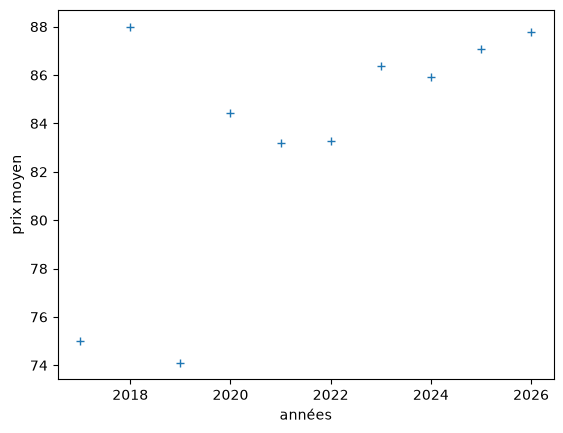

In [85]:
#Evolution du prix moyen des visites en fonction des années 
import matplotlib.pyplot as plt
import numpy as np

df['date_application_visite'] = pd.to_datetime(df['date_application_visite'])
df['annees'] =df['date_application_visite'].dt.year         #Nouvelle colonne avec les années extraites des dates

Y = df.groupby('annees')['prix_visite'].mean()
Y = Y.to_numpy()
annees=np.arange(2017, 2027)

plt.plot(annees, Y, '+')
plt.xlabel('années')
plt.ylabel('prix moyen')
plt.show()
#df